In [ ]:
import numpy as np
import pylab as plt
import pandas as pd
import h5py

In [ ]:
f = h5py.File('sample_2e7_design_precessing_higherordermodes_3detectors.h5')
f.keys()
#f['det'].shape[0]

<KeysViewHDF5 ['chi1x', 'chi1y', 'chi1z', 'chi2x', 'chi2y', 'chi2z', 'dec', 'det', 'iota', 'mtot', 'psi', 'q', 'ra', 'snr', 'z']>

il mio dataset: 
N*K = 2*10^7 components * 13 features 

gw detection: lavorare con un algoritmo che preferisce completenes a efficency 

det are my labels, 1 for detection (snr>12) 0 for non detection (snr<12)

ho tanti dati, la mia idea è splittarli tra train test e validation set

#scelta del migliore algoritmo su train test set 
    ridurre il numero di components per scegliere algoritmo ottimale 
    scegliere il best algoritmo: 
    tunare il best algoritmo con cv 

applicare il best algoritmo a tutto il set 
testarlo sul full validation set

DEFINING THE N*K MATRIX AND THE LABELS

In [ ]:
labels=f['det']
feature_names = ['chi1x', 'chi1y', 'chi1z', 'chi2x', 'chi2y', 'chi2z', 'dec',  'iota', 'mtot', 'psi', 'q', 'ra', 'z']
X = np.column_stack([f[name] for name in feature_names])
print(X.shape)

#check che non ci siano Nan

valid_mask = np.all(np.isfinite(X), axis=1)
X = X[valid_mask]
labels = labels[valid_mask]

(20000000, 13)


train validation test set split

In [ ]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, labels_train_val, labels_test = train_test_split(
    X, labels,
    test_size=0.30,
    stratify=labels,       # Mantiene il rapporto det=1 / det=0
    random_state=42  
)

print(X_train_val.shape)

(14000000, 13)


Riduco le dimensioni del dataset per trovare iperparametri/modello 
faccio i miei studi su 1/1000 del dataset (train_validation)

In [ ]:
from sklearn.model_selection import train_test_split


X_sub, _, labels_sub, _ = train_test_split(
    X_train_val, labels_train_val,
    train_size=0.001,        
    stratify=labels_train_val,     
    random_state=42
)



NameError: name 'X_train_val' is not defined

cv k-fold su Random forest algoritmo
scelto random forest perchè lavoro con tanti dati ed è embarassing parallelizzabile 

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve, roc_curve, auc, average_precision_score


rf = RandomForestClassifier(random_state=42, n_jobs=-1)

param_dist = {
    'n_estimators': [100, 200, 300], #numero di alberi
    'max_features': ['sqrt', 'log2', 0.5], #numero di features  
    'max_depth': [10, 15, 20, None], #profondità di ogni albero
    'min_samples_leaf': [1, 2, 5, 10],
}

def cross_val(estimator,param_dist,n_jobs,n_iter,k):
    cv = StratifiedKFold(shuffle=True, random_state=42,n_splits=k) 
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=n_iter,
        cv=cv,
        scoring='average_precision', #ottimizza per la curva Efficiency vs Completeness
        random_state=42,
        n_jobs=n_jobs,
        verbose=1
    )
    return search


    
search=cross_val(rf,param_dist,-1,n_iter=25,k=5)
search.fit(X_sub, labels_sub)
best_rf = search.best_estimator_
print("Migliori iperparametri trovati:")
print(search.best_params_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Migliori iperparametri trovati:
{'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 15}


calcolo di curve COMPLETENESS vs EFFICENCY 

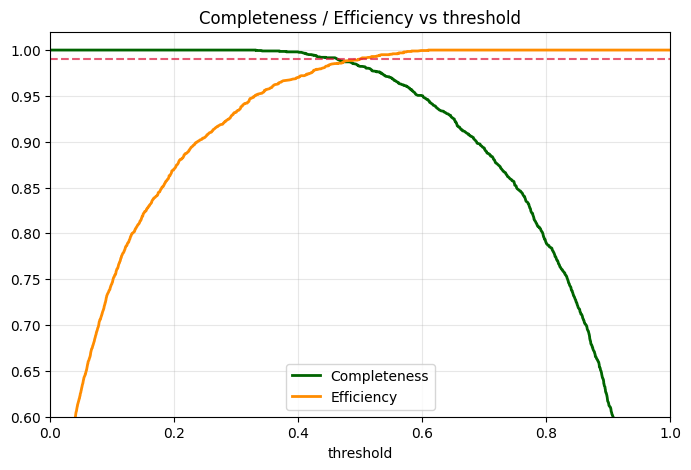


Per ottenere Completeness >= 99.0%:
-> Imposta soglia p_th = 0.4631
-> Efficiency risultante = 98.52% (Contamination = 1.48%)


In [ ]:

y_probs = best_rf.predict_proba(X_sub)[:, 1]

# Calcolo di Efficiency, Completeness 
efficiency, completeness, thresholds = precision_recall_curve(labels_sub, y_probs)
pr_auc = auc(completeness, efficiency)

fig,ax = plt.subplots(figsize=(8, 5))

#Completeness e Efficiency vs soglia 
ax.plot(thresholds, completeness[:-1], lw=2, color='darkgreen', label='Completeness')
ax.plot(thresholds, efficiency[:-1], lw=2, color='darkorange', label='Efficiency')
ax.axhline(0.99, color='crimson', linestyle='--', alpha=0.7)
ax.set_xlabel('threshold')
ax.set_ylabel('')
ax.set_title('Completeness / Efficiency vs threshold')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.6, 1.02])
ax.grid(True, alpha=0.3)
ax.legend(loc='best')

plt.show()

target_completeness = 0.99
# Trova la soglia più alta che garantisce ancora completeness >= 99%
valid_idx = np.where(completeness[:-1] >= target_completeness)[0]
best_thresh = thresholds[valid_idx[-1]]
eff_at_target = efficiency[valid_idx[-1]]

print(f"\nPer ottenere Completeness >= {target_completeness:.1%}:")
print(f"-> Imposta soglia p_th = {best_thresh:.4f}")
print(f"-> Efficiency risultante = {eff_at_target:.2%} (Contamination = {1 - eff_at_target:.2%})")

# Predizione finale con la soglia personalizzata (invece del default 0.5)
y_pred_custom = (y_probs >= best_thresh).astype(int)

LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
X_sub_scaled = scaler.fit_transform(X_sub)


logr = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000, random_state=42)


param_grid_lr = {   #c parametro inversamente proporzionale al parametro di penalizzazione lambda della cost function da minimizzare (cost function j(beta))
    'C': np.logspace(-4, 3, 15),
}

search_lr=cross_val(logr,param_grid_lr,-1,25,5)
search_lr.fit(X_sub_scaled, labels_sub)
best_lr = search_lr.best_estimator_
print("Migliori iperparametri trovati:")
print(search_lr.best_params_)



c:\Users\ricca\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 15 is smaller than n_iter=25. Running 15 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Migliori iperparametri trovati:
{'C': np.float64(3.1622776601683795)}


c:\Users\ricca\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


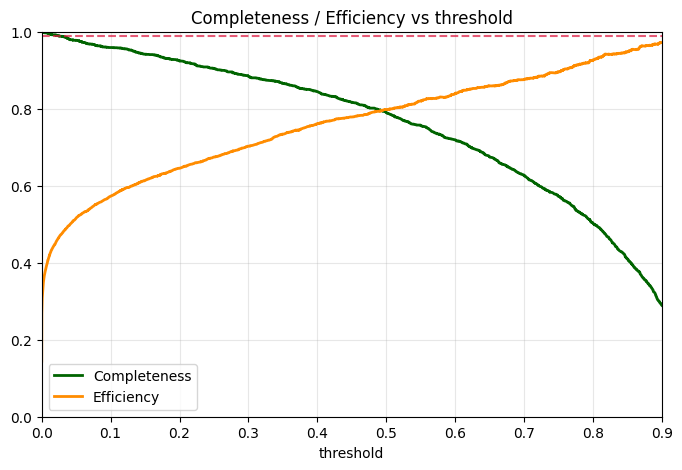


Per ottenere Completeness >= 99.0%:
-> Imposta soglia p_th = 0.0241
-> Efficiency risultante = 46.42% (Contamination = 53.58%)


In [ ]:
y_probs_lr = best_lr.predict_proba(X_sub_scaled)[:, 1]

# Calcolo di Efficiency, Completeness 
efficiency_lr, completeness_lr, thresholds_lr = precision_recall_curve(labels_sub, y_probs_lr)
pr_auc = auc(completeness_lr, efficiency_lr)

#plot
fig,ax = plt.subplots(figsize=(8, 5))
#Completeness e Efficiency vs soglia 
ax.plot(thresholds_lr, completeness_lr[:-1], lw=2, color='darkgreen', label='Completeness')
ax.plot(thresholds_lr, efficiency_lr[:-1], lw=2, color='darkorange', label='Efficiency')
ax.axhline(0.99, color='crimson', linestyle='--', alpha=0.7)
ax.set_xlabel('threshold')
ax.set_ylabel('')
ax.set_title('Completeness / Efficiency vs threshold')
ax.set_xlim([0.0, 0.9])
ax.set_ylim([0.0, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc='best')

plt.show()


target_completeness = 0.99
# Trova la soglia più alta che garantisce ancora completeness >= 99%
valid_idx_lr = np.where(completeness_lr[:-1] >= target_completeness)[0]
best_thresh_lr = thresholds_lr[valid_idx_lr[-1]]
eff_at_target_lr = efficiency_lr[valid_idx_lr[-1]]

print(f"\nPer ottenere Completeness >= {target_completeness:.1%}:")
print(f"-> Imposta soglia p_th = {best_thresh_lr:.4f}")
print(f"-> Efficiency risultante = {eff_at_target_lr:.2%} (Contamination = {1 - eff_at_target_lr:.2%})")

# Predizione con la soglia personalizzata (invece del default 0.5)
y_pred_custom_lr = (y_probs >= best_thresh_lr).astype(int)




BOOSTING 

Uso histboostgradientclassifier perchè più efficace computazionalmente per grandi dataset 

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(
    early_stopping=True, #stoppa se 
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)


param_dist_hgb = {
    'learning_rate': [0.02, 0.05, 0.1, 0.2],
    'max_iter': [100, 200, 400, 600],
    'max_leaf_nodes': [15, 31, 63, 127],
    'max_depth': [4, 6, 8, None],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': [0.0, 0.1, 1.0, 10.0]
}


search_hgb=cross_val(hgb,param_dist_hgb,-1,25,5)
search_hgb.fit(X_sub, labels_sub)
best_hgb = search_hgb.best_estimator_
print("Migliori iperparametri trovati:")
print(search_hgb.best_params_)


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Migliori iperparametri trovati:
{'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_iter': 600, 'max_depth': 8, 'learning_rate': 0.05, 'l2_regularization': 10.0}


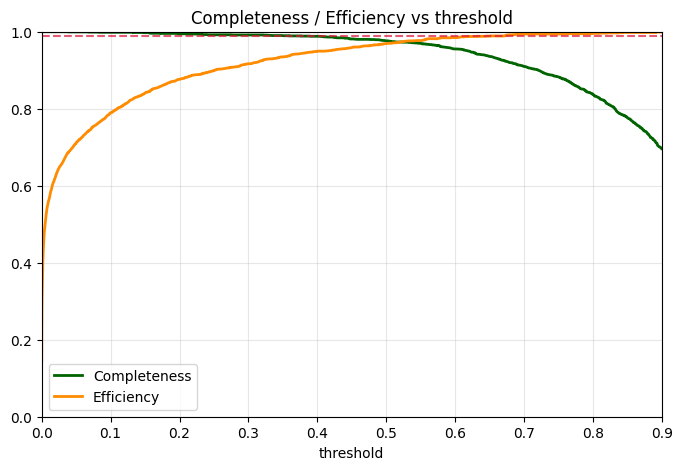


Per ottenere Completeness >= 99.0%:
-> Imposta soglia p_th = 0.3487
-> Efficiency risultante = 93.46% (Contamination = 6.54%)


In [ ]:
y_probs_hgb = best_hgb.predict_proba(X_sub)[:, 1]

# Calcolo di Efficiency, Completeness 
efficiency_hgb, completeness_hgb, thresholds_hgb = precision_recall_curve(labels_sub, y_probs_hgb)
pr_auc = auc(completeness_hgb, efficiency_hgb)

#plot
fig,ax = plt.subplots(figsize=(8, 5))
#Completeness e Efficiency vs soglia 
ax.plot(thresholds_hgb, completeness_hgb[:-1], lw=2, color='darkgreen', label='Completeness')
ax.plot(thresholds_hgb, efficiency_hgb[:-1], lw=2, color='darkorange', label='Efficiency')
ax.axhline(0.99, color='crimson', linestyle='--', alpha=0.7)
ax.set_xlabel('threshold')
ax.set_ylabel('')
ax.set_title('Completeness / Efficiency vs threshold')
ax.set_xlim([0.0, 0.9])
ax.set_ylim([0.0, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc='best')

plt.show()


target_completeness = 0.99
# Trova la soglia più alta che garantisce ancora completeness >= 99%
valid_idx_hgb = np.where(completeness_hgb[:-1] >= target_completeness)[0]
best_thresh_hgb = thresholds_hgb[valid_idx_hgb[-1]]
eff_at_target_hgb = efficiency_hgb[valid_idx_hgb[-1]]

print(f"\nPer ottenere Completeness >= {target_completeness:.1%}:")
print(f"-> Imposta soglia p_th = {best_thresh_hgb:.4f}")
print(f"-> Efficiency risultante = {eff_at_target_hgb:.2%} (Contamination = {1 - eff_at_target_hgb:.2%})")

# Predizione con la soglia personalizzata (invece del default 0.5)
y_pred_custom_lr = (y_probs >= best_thresh_hgb).astype(int)


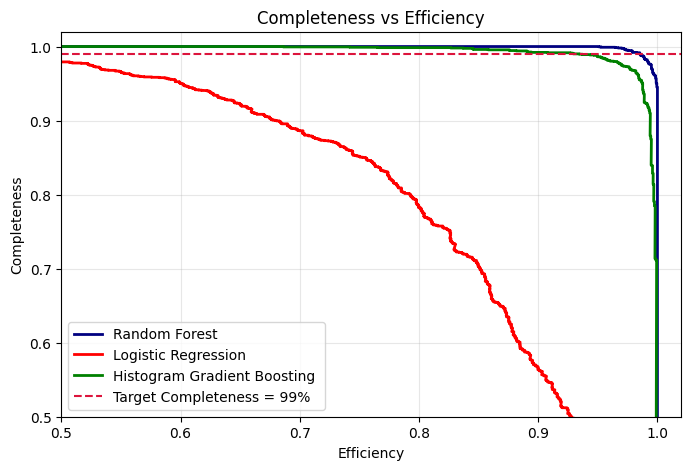

In [ ]:


fig, ax = plt.subplots(figsize=(8, 5))

# Completeness vs Efficiency 
ax.plot(efficiency, completeness, lw=2, color='navy', label=f'Random Forest')
ax.plot(efficiency_lr, completeness_lr, lw=2, color='red', label=f'Logistic Regression')
ax.plot(efficiency_hgb, completeness_hgb, lw=2, color='green', label=f'Histogram Gradient Boosting ')
ax.axhline(0.99, color='crimson', linestyle='--', label='Target Completeness = 99%')
ax.set_xlabel('Efficiency')
ax.set_ylabel('Completeness')
ax.set_title('Completeness vs Efficiency')
ax.set_xlim([0.50, 1.02])
ax.set_ylim([0.50, 1.02])
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left')
 
plt.show()



SCELGO RANDOM FOREST 

In [ ]:
X_train_val32 = X_train_val.astype(np.float32)

Ho provato a cross validare i parametri sul dataset intero, troppo costo computazionale

In [ ]:

'''
rf = RandomForestClassifier()
param_dist = {
    'n_estimators': [100], #numero di alberi
    'max_features': [0.5], #numero di features  
    'max_depth': [10, 15, 20], #profondità di ogni albero
    'min_samples_leaf': [5],
}
search=cross_val(rf,param_dist,4,n_iter=10,k=3)
search.fit(X_train_val32,labels_train_val )
best_rf = search.best_estimator_
print("Migliori iperparametri trovati:")
print(search.best_params_)'''

'\nrf = RandomForestClassifier()\nparam_dist = {\n    \'n_estimators\': [100], #numero di alberi\n    \'max_features\': [0.5], #numero di features  \n    \'max_depth\': [10, 15, 20], #profondità di ogni albero\n    \'min_samples_leaf\': [5],\n}\nsearch=cross_val(rf,param_dist,4,n_iter=10,k=3)\nsearch.fit(X_train_val32,labels_train_val )\nbest_rf = search.best_estimator_\nprint("Migliori iperparametri trovati:")\nprint(search.best_params_)'

fit sul train_dataset con parametri cross validati sul dataset ridotto 

In [ ]:
from joblib import parallel_backend
rf_tot = RandomForestClassifier(max_depth=15, 
                                 max_features='sqrt', 
                                 min_samples_leaf=10,
                                 n_estimators=100, 
                                 n_jobs=-1,
                                 random_state=42,
                                 verbose= 2)
with parallel_backend('threading', n_jobs=-1):
    rf_tot.fit(X_train_val32, labels_train_val)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.


building tree 5 of 100
building tree 1 of 100
building tree 10 of 100
building tree 4 of 100
building tree 15 of 100
building tree 16 of 100
building tree 2 of 100
building tree 6 of 100
building tree 11 of 100
building tree 3 of 100
building tree 12 of 100
building tree 13 of 100
building tree 9 of 100
building tree 14 of 100
building tree 7 of 100
building tree 8 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100
building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100


[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:  3.5min


building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100
building tree 40 of 100
building tree 41 of 100
building tree 42 of 100
building tree 43 of 100
building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67

[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed: 22.3min finished


In [ ]:
y_probs_tot = rf_tot.predict_proba(X_test)[:, 1]



[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done   9 tasks      | elapsed:    1.2s
[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    7.6s finished


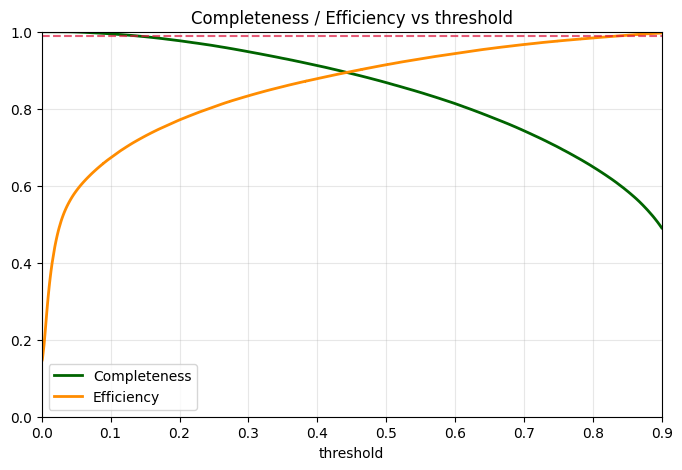


Per ottenere Completeness >= 99.0%:
-> Imposta soglia p_th = 0.1327
-> Efficiency risultante = 71.16% (Contamination = 28.84%)


In [ ]:
# Calcolo di Efficiency, Completeness 
efficiency_tot, completeness_tot, thresholds_tot = precision_recall_curve(labels_test, y_probs_tot)
pr_auc = auc(completeness_tot, efficiency_tot)

#plot
fig,ax = plt.subplots(figsize=(8, 5))
#Completeness e Efficiency vs soglia 
ax.plot(thresholds_tot, completeness_tot[:-1], lw=2, color='darkgreen', label='Completeness')
ax.plot(thresholds_tot, efficiency_tot[:-1], lw=2, color='darkorange', label='Efficiency')
ax.axhline(0.99, color='crimson', linestyle='--', alpha=0.7)
ax.set_xlabel('threshold')
ax.set_ylabel('')
ax.set_title('Completeness / Efficiency vs threshold')
ax.set_xlim([0.0, 0.9])
ax.set_ylim([0.0, 1.0])
ax.grid(True, alpha=0.3)
ax.legend(loc='best')

plt.show()


target_completeness = 0.99
# Trova la soglia più alta che garantisce ancora completeness >= 99%
valid_idx_tot = np.where(completeness_tot[:-1] >= target_completeness)[0]
best_thresh_tot = thresholds_tot[valid_idx_tot[-1]]
eff_at_target_tot= efficiency_tot[valid_idx_tot[-1]]

print(f"\nPer ottenere Completeness >= {target_completeness:.1%}:")
print(f"-> Imposta soglia p_th = {best_thresh_tot:.4f}")
print(f"-> Efficiency risultante = {eff_at_target_tot:.2%} (Contamination = {1 - eff_at_target_tot:.2%})")

# Predizione con la soglia personalizzata (invece del default 0.5)
y_pred_custom_tot = (y_probs_tot >= best_thresh_tot).astype(int)

ROC AUC: 0.9941
Average Precision (Area Completeness-Efficiency): 0.9671


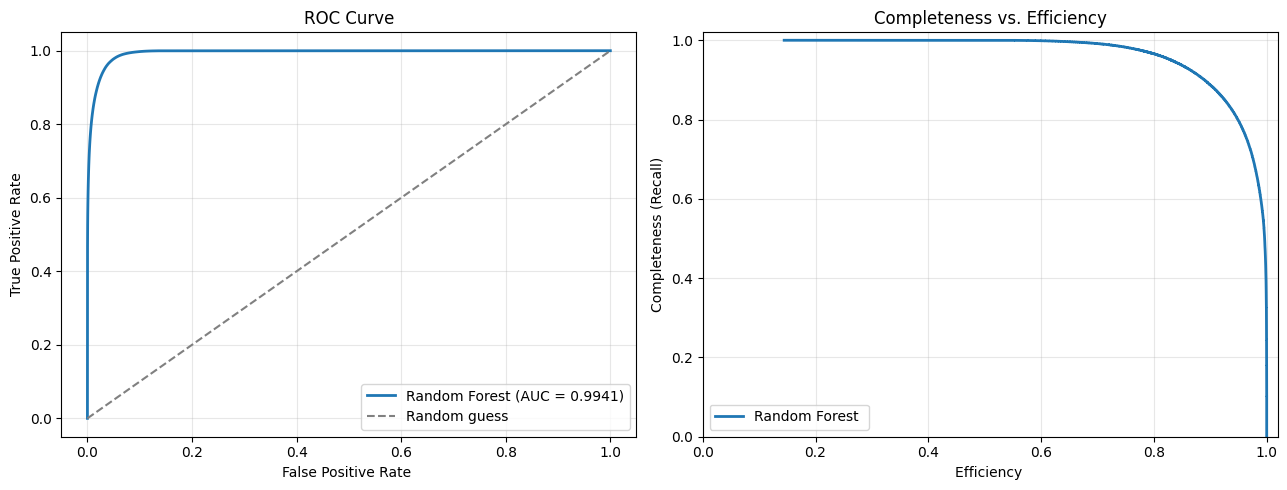

In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score)
#curva ROC (FPR vs TPR) e AUC
fpr, tpr, roc_thresholds = roc_curve(labels_test, y_probs_tot)
roc_auc = roc_auc_score(labels_test, y_probs_tot)

#curva Efficiency vs Completeness e Average Precision
efficiency, completeness, pr_thresholds = precision_recall_curve(labels_test, y_probs_tot)
ap_score = average_precision_score(labels_test, y_probs_tot)

print(f"ROC AUC: {roc_auc:.4f}")
print(f"Average Precision (Area Completeness-Efficiency): {ap_score:.4f}")

#Plot 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Pannello 1: Curva ROC ---
axes[0].plot(fpr, tpr, lw=2, label=f'Random Forest (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guess')
axes[0].set_xlabel('False Positive Rate ')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# --- Pannello 2: Completeness vs Efficiency ---
# Nota: nella letteratura astrofisica (es. Fig. 9.23 di Ivezic et al.) si plotta spesso
# efficiency sull'asse X e completeness sull'asse Y (o viceversa)
axes[1].plot(efficiency, completeness, lw=2, label=f'Random Forest ')
axes[1].set_xlabel('Efficiency ')
axes[1].set_ylabel('Completeness (Recall)')
axes[1].set_title('Completeness vs. Efficiency')
axes[1].set_xlim([0.0, 1.02])
axes[1].set_ylim([0.0, 1.02])
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

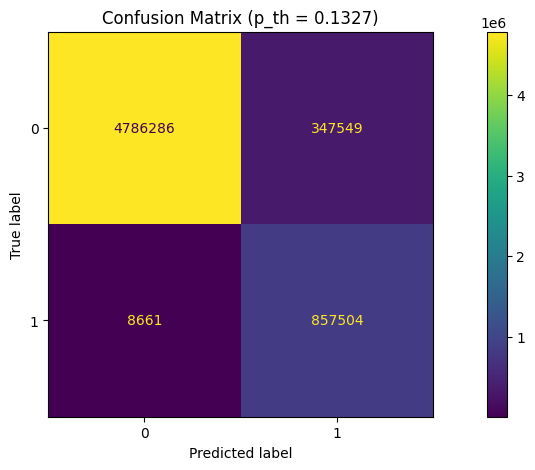

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    labels_test,
    y_pred_custom_tot,
    values_format='d',
    ax=ax
)
ax.set_title(f'Confusion Matrix (p_th = {best_thresh_tot:.4f})')

plt.show()